
 METHOD 1: THINNING
Star mean: 5.99268
Star variance: 5.965046242831213
Sky mean: 4.001805
Sky variance: 4.001911751533758
Star-sky correlation: -0.004116348914423461
Total mean: 9.994485
Total variance: 9.926734218446093
P(total = 10): 0.12613
Number of windows with 10 detections: 25226
P(exactly 6 star | total = 10): 0.25414255133592323
P(total >= 15): 0.08231

 METHOD 2: DIRECT
Star mean: 6.0002
Star variance: 5.9903499117495596
Sky mean: 3.994175
Sky variance: 3.9987310630303154
Star-sky correlation: -0.0010509982835672084
Total mean: 9.994375
Total variance: 9.978793253341268
P(total = 10): 0.12477
Number of windows with 10 detections: 24954
P(exactly 6 star | total = 10): 0.24909834094734312
P(total >= 15): 0.08382

THEORETICAL RESULTS
Total mean: 10
Total variance: 10
P(total = 10): 0.1251100357211333
P(total >= 15): 0.0834584729346628

FIRST DETECTION RESULTS
P(star first): 0.600705
P(star first and within 1 second): 0.519115
Expected time until both types are detected: 1.5804

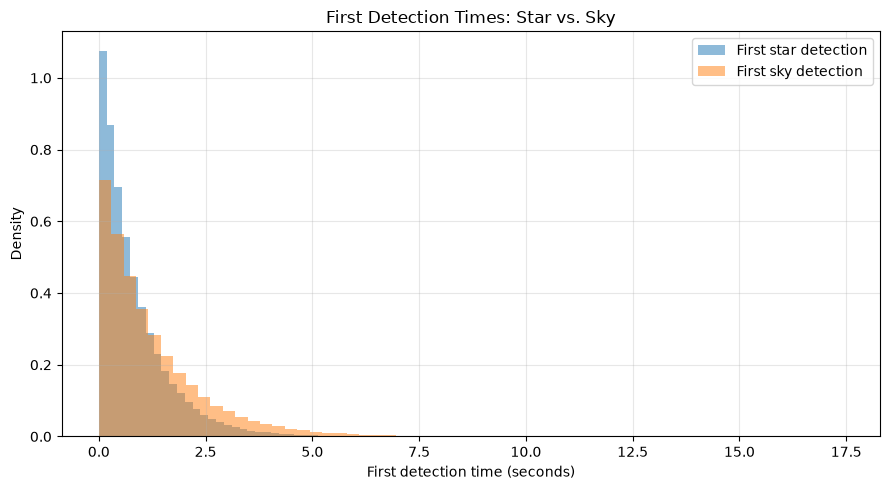

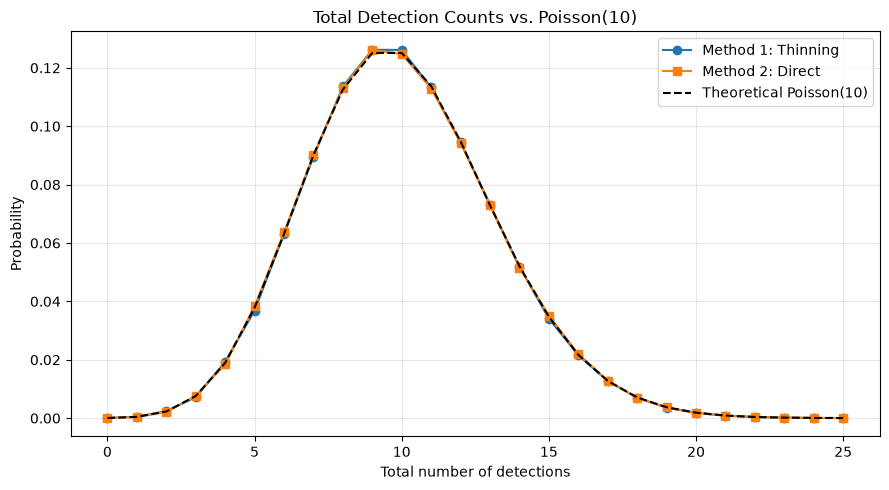

In [5]:

import numpy as np
import math
import matplotlib.pyplot as plt
import os

# Parameters
N = 200_000
q = 0.4
star_rate = 3
sky_rate = 2
T = 5

detected_star_rate = q * star_rate
detected_sky_rate = q * sky_rate

rng = np.random.default_rng(2026)

# ==========================================
# METHOD 1: GENERATE ORIGINAL PHOTONS, THEN THIN
# ==========================================

star_original = rng.poisson(star_rate * T, N)
sky_original = rng.poisson(sky_rate * T, N)

star1 = rng.binomial(star_original, q)
sky1 = rng.binomial(sky_original, q)

total1 = star1 + sky1

# ==========================================
# METHOD 2: GENERATE DETECTED PROCESSES DIRECTLY
# ==========================================

star2 = rng.poisson(detected_star_rate * T, N)
sky2 = rng.poisson(detected_sky_rate * T, N)

total2 = star2 + sky2

# ==========================================
# SUMMARY FUNCTION
# ==========================================

def summarize(star, sky, total, method):

    selected = total == 10

    print("\n", method)
    print("=" * 45)

    print("Star mean:", np.mean(star))
    print("Star variance:", np.var(star, ddof=1))

    print("Sky mean:", np.mean(sky))
    print("Sky variance:", np.var(sky, ddof=1))

    print("Star-sky correlation:",
          np.corrcoef(star, sky)[0, 1])

    print("Total mean:", np.mean(total))
    print("Total variance:", np.var(total, ddof=1))

    print("P(total = 10):", np.mean(selected))
    print("Number of windows with 10 detections:",
          np.sum(selected))

    print("P(exactly 6 star | total = 10):",
          np.mean(star[selected] == 6))

    print("P(total >= 15):", np.mean(total >= 15))


# Run both methods
summarize(star1, sky1, total1, "METHOD 1: THINNING")
summarize(star2, sky2, total2, "METHOD 2: DIRECT")

# ==========================================
# THEORETICAL POISSON(10)
# ==========================================

def poisson_pmf(k, rate=10):
    return math.exp(-rate) * rate**k / math.factorial(k)

p10 = poisson_pmf(10)
p15 = 1 - sum(poisson_pmf(k) for k in range(15))

print("\nTHEORETICAL RESULTS")
print("=" * 45)
print("Total mean:", 10)
print("Total variance:", 10)
print("P(total = 10):", p10)
print("P(total >= 15):", p15)

# ==========================================
# FIRST DETECTION TIMES
# ==========================================

T_star = rng.exponential(
    scale=1 / detected_star_rate, size=N
)

T_sky = rng.exponential(
    scale=1 / detected_sky_rate, size=N
)

T_first = np.minimum(T_star, T_sky)
star_first = T_star < T_sky
M = np.maximum(T_star, T_sky)

print("\nFIRST DETECTION RESULTS")
print("=" * 45)

print("P(star first):", np.mean(star_first))

print("P(star first and within 1 second):",
      np.mean(star_first & (T_first <= 1)))

print("Expected time until both types are detected:",
      np.mean(M))

print("Correlation between first detection time and type:",
      np.corrcoef(T_first, star_first.astype(float))[0, 1])

# ==========================================
# FIGURE 1: FIRST DETECTION TIMES
# ==========================================

fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(T_star, bins=60, density=True,
        alpha=0.5, label="First star detection")

ax.hist(T_sky, bins=60, density=True,
        alpha=0.5, label="First sky detection")

ax.set_xlabel("First detection time (seconds)")
ax.set_ylabel("Density")
ax.set_title("First Detection Times: Star vs. Sky")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.expanduser("~/Downloads/HW4 P2 1.pdf"), bbox_inches="tight")
plt.show()
plt.close(fig)

# ==========================================
# FIGURE 2: FULL POISSON PMF COMPARISON
# ==========================================

k_values = np.arange(0, 26)

theoretical_pmf = np.array([
    poisson_pmf(int(k)) for k in k_values
])

empirical_pmf1 = (
    np.bincount(total1, minlength=26)[:26] / N
)

empirical_pmf2 = (
    np.bincount(total2, minlength=26)[:26] / N
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(k_values, empirical_pmf1, "o-",
        label="Method 1: Thinning")

ax.plot(k_values, empirical_pmf2, "s-",
        label="Method 2: Direct")

ax.plot(k_values, theoretical_pmf, "k--",
        label="Theoretical Poisson(10)")

ax.set_xlabel("Total number of detections")
ax.set_ylabel("Probability")
ax.set_title("Total Detection Counts vs. Poisson(10)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.expanduser("~/Downloads/HW8 p2 2.pdf"), bbox_inches="tight")
plt.show()
plt.close(fig)


THINNING RESULTS
----------------
Proposed points: 14275
Retained points: 8663
Fraction retained: 0.6068651488616462
Theoretical fraction: 0.6


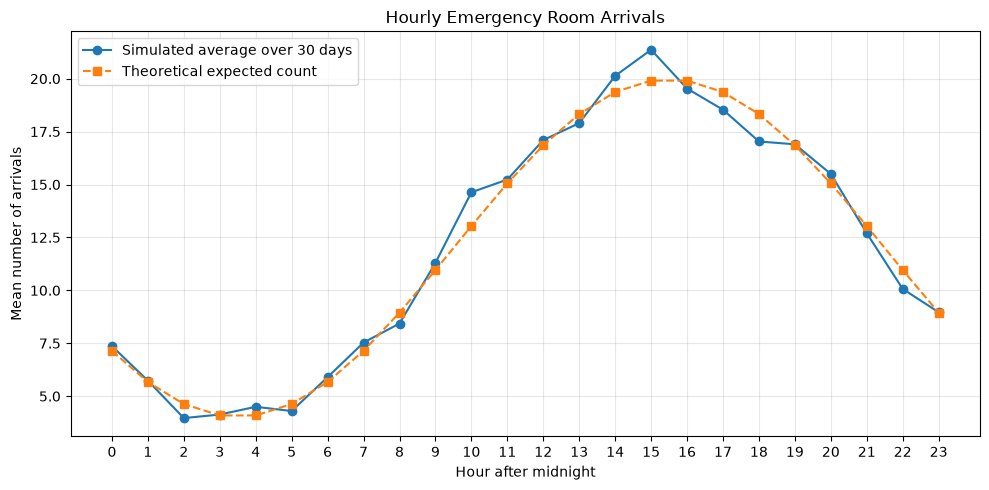


HOURLY COMPARISON
-----------------
Largest absolute deviation: 1.5921032831829294
Hour with largest deviation: 10

3 AM TO 4 AM
------------
Daily counts: [5 3 3 3 4 4 4 5 5 2 1 4 4 7 5 5 4 6 7 4 3 5 9 5 2 3 5 2 3 2]
Sample mean: 4.133333333333334
Sample variance: 2.9471264367816095
Theoretical mean and variance: 4.091072564277042
Approximate SE of sample variance: 1.1189998810937931

MAXIMUM LIKELIHOOD RESULTS
--------------------------
a estimate: 12.0319443997912
b estimate: 8.032949313750047
phi estimate: 15.858211111809315
Fitted log-likelihood: 13917.225477005257
Constant-rate estimate: 12.031944444444445
Constant-rate log-likelihood: 12886.77689341078
Log-likelihood difference: 1030.448583594476
Likelihood-ratio statistic: 2060.897167188952


In [6]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# Parameters
rng = np.random.default_rng(2026)
T = 720
days = 30
lambda_max = 20

def lam(t):
    return 12 + 8 * np.cos(np.pi * (t - 16) / 12)

def Lambda(s, t):
    return (
        12 * (t - s)
        + (96 / np.pi) * (
            np.sin(np.pi * (t - 16) / 12)
            - np.sin(np.pi * (s - 16) / 12)
        )
    )

# 1. Generate the homogeneous Poisson process
n_proposed = rng.poisson(lambda_max * T)
proposed_times = np.sort(rng.uniform(0, T, n_proposed))

# 2. Thin the proposed points
keep = rng.random(n_proposed) < lam(proposed_times) / lambda_max
arrival_times = proposed_times[keep]

n_kept = len(arrival_times)
fraction_kept = n_kept / n_proposed

print("THINNING RESULTS")
print("----------------")
print("Proposed points:", n_proposed)
print("Retained points:", n_kept)
print("Fraction retained:", fraction_kept)
print("Theoretical fraction:", 0.60)

# 3. Count arrivals in each clock hour
hour_counts = np.bincount(
    np.floor(arrival_times).astype(int),
    minlength=T
)

daily_counts = hour_counts.reshape(days, 24)

# Average arrivals in each clock hour over 30 days
mean_hourly_counts = daily_counts.mean(axis=0)

# Exact expected count in each one-hour interval
hourly_expected = np.array([
    Lambda(h, h + 1) for h in range(24)
])

# Plot simulated hourly means against exact expectations
hours = np.arange(24)

plt.figure(figsize=(10, 5))
plt.plot(
    hours, mean_hourly_counts, "o-",
    label="Simulated average over 30 days"
)
plt.plot(
    hours, hourly_expected, "s--",
    label="Theoretical expected count"
)
plt.xlabel("Hour after midnight")
plt.ylabel("Mean number of arrivals")
plt.title("Hourly Emergency Room Arrivals")
plt.xticks(hours)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(os.path.expanduser("~/Downloads/HW8 p3.pdf"), bbox_inches="tight")
plt.show()
plt.close()

# Largest absolute difference in the hourly plot
hourly_deviations = np.abs(mean_hourly_counts - hourly_expected)

print("\nHOURLY COMPARISON")
print("-----------------")
print("Largest absolute deviation:",
      np.max(hourly_deviations))
print("Hour with largest deviation:",
      np.argmax(hourly_deviations))

# 4. Arrivals between 3 am and 4 am
counts_3_to_4 = daily_counts[:, 3]

sample_mean = np.mean(counts_3_to_4)
sample_variance = np.var(counts_3_to_4, ddof=1)
theoretical_mean = Lambda(3, 4)

print("\n3 AM TO 4 AM")
print("------------")
print("Daily counts:", counts_3_to_4)
print("Sample mean:", sample_mean)
print("Sample variance:", sample_variance)
print("Theoretical mean and variance:", theoretical_mean)

# Approximate standard error of the sample variance
variance_se = np.sqrt(
    (theoretical_mean + 2 * theoretical_mean**2) / days
)
print("Approximate SE of sample variance:", variance_se)

# 5. Maximum likelihood estimation
# lambda(t) = a + b*cos(pi*(t-phi)/12)

def negative_log_likelihood(params):
    a, b, phi = params

    # Require a positive fitted rate
    if a <= abs(b):
        return 1e100

    fitted_rates = a + b * np.cos(
        np.pi * (arrival_times - phi) / 12
    )

    if np.any(fitted_rates <= 0):
        return 1e100

    # Over 720 hours, the cosine integral is zero
    log_likelihood = (
        np.sum(np.log(fitted_rates)) - 720 * a
    )

    return -log_likelihood

initial_guess = [10, 5, 14]

fit = minimize(
    negative_log_likelihood,
    initial_guess,
    method="Nelder-Mead",
    options={"maxiter": 100000, "xatol": 1e-11}
)

a_hat, b_hat, phi_hat = fit.x
fitted_log_likelihood = -fit.fun

# Constant-rate model
constant_rate = n_kept / T
constant_log_likelihood = (
    n_kept * np.log(constant_rate) - n_kept
)

# Likelihood-ratio comparison
LR = 2 * (
    fitted_log_likelihood - constant_log_likelihood
)

print("\nMAXIMUM LIKELIHOOD RESULTS")
print("--------------------------")
print("a estimate:", a_hat)
print("b estimate:", b_hat)
print("phi estimate:", phi_hat)
print("Fitted log-likelihood:", fitted_log_likelihood)
print("Constant-rate estimate:", constant_rate)
print("Constant-rate log-likelihood:",
      constant_log_likelihood)
print("Log-likelihood difference:",
      fitted_log_likelihood - constant_log_likelihood)
print("Likelihood-ratio statistic:", LR)
